Features: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Classes: ['setosa' 'versicolor' 'virginica']

First five rows:
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                5.1               3.5                1.4               0.2   
1                4.9               3.0                1.4               0.2   
2                4.7               3.2                1.3               0.2   
3                4.6               3.1                1.5               0.2   
4                5.0               3.6                1.4               0.2   

  Species  
0  setosa  
1  setosa  
2  setosa  
3  setosa  
4  setosa  

 Gaussian Naive Bayes
Accuracy: 0.9667
Precision: 0.9697
Recall: 0.9667
F1 Score: 0.9666

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0

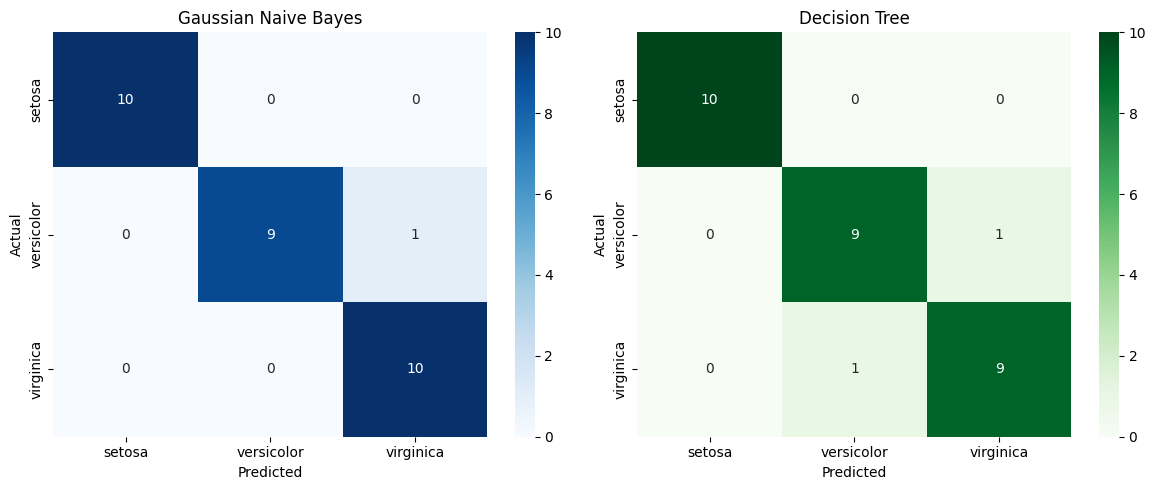


Model Comparison:
                  Model  Accuracy  Precision  Recall  F1 Score
0  Gaussian Naive Bayes    0.9667     0.9697  0.9667    0.9666
1         Decision Tree    0.9333     0.9333  0.9333    0.9333


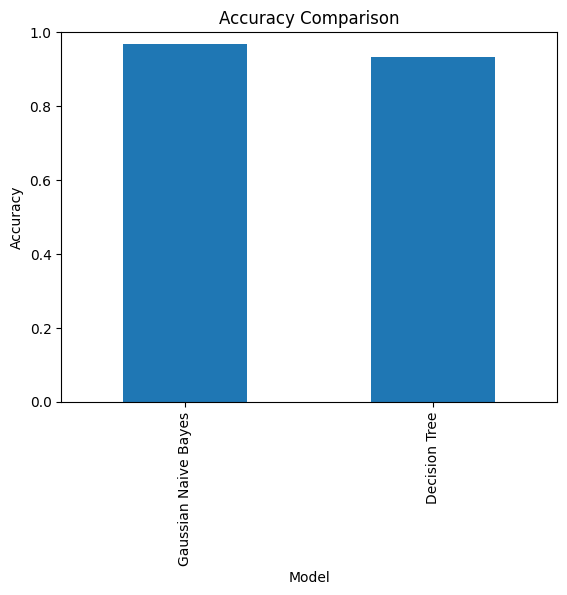

In [1]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# 1. Load Iris dataset
iris = load_iris()

X = iris.data
y = iris.target

# Feature and target names
print("Features:", iris.feature_names)
print("Classes:", iris.target_names)

# Display dataset
df = pd.DataFrame(X, columns=iris.feature_names)
df["Species"] = [iris.target_names[i] for i in y]

print("\nFirst five rows:")
print(df.head())

# 2. Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# 3. Train Gaussian Naive Bayes
nb_model = GaussianNB()
nb_model.fit(X_train, y_train)

# Predict using Gaussian Naive Bayes
nb_pred = nb_model.predict(X_test)

# 4. Train Decision Tree using same split
dt_model = DecisionTreeClassifier(
    random_state=42
)
dt_model.fit(X_train, y_train)

# Predict using Decision Tree
dt_pred = dt_model.predict(X_test)

# 5. Evaluation function
def evaluate_model(name, y_test, y_pred):
    print("\n", name)
    print("Accuracy:",
          round(accuracy_score(y_test, y_pred), 4))

    print("Precision:",
          round(precision_score(
              y_test, y_pred, average="macro"
          ), 4))

    print("Recall:",
          round(recall_score(
              y_test, y_pred, average="macro"
          ), 4))

    print("F1 Score:",
          round(f1_score(
              y_test, y_pred, average="macro"
          ), 4))

    print("\nClassification Report:")
    print(classification_report(
        y_test, y_pred,
        target_names=iris.target_names
    ))

# Evaluate both models
evaluate_model("Gaussian Naive Bayes", y_test, nb_pred)
evaluate_model("Decision Tree", y_test, dt_pred)

# 6. Confusion matrices
nb_cm = confusion_matrix(y_test, nb_pred)
dt_cm = confusion_matrix(y_test, dt_pred)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.heatmap(
    nb_cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=iris.target_names,
    yticklabels=iris.target_names,
    ax=axes[0]
)
axes[0].set_title("Gaussian Naive Bayes")
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("Actual")

sns.heatmap(
    dt_cm, annot=True, fmt="d", cmap="Greens",
    xticklabels=iris.target_names,
    yticklabels=iris.target_names,
    ax=axes[1]
)
axes[1].set_title("Decision Tree")
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("Actual")

plt.tight_layout()
plt.show()

# 7. Compare model performance
results = pd.DataFrame({
    "Model": ["Gaussian Naive Bayes", "Decision Tree"],
    "Accuracy": [
        accuracy_score(y_test, nb_pred),
        accuracy_score(y_test, dt_pred)
    ],
    "Precision": [
        precision_score(y_test, nb_pred, average="macro"),
        precision_score(y_test, dt_pred, average="macro")
    ],
    "Recall": [
        recall_score(y_test, nb_pred, average="macro"),
        recall_score(y_test, dt_pred, average="macro")
    ],
    "F1 Score": [
        f1_score(y_test, nb_pred, average="macro"),
        f1_score(y_test, dt_pred, average="macro")
    ]
})

print("\nModel Comparison:")
print(results.round(4))

# 8. Compare accuracy graphically
results.set_index("Model")["Accuracy"].plot(
    kind="bar", ylim=(0, 1),
    title="Accuracy Comparison"
)

plt.ylabel("Accuracy")
plt.show()
